<a href="https://colab.research.google.com/github/Tol1bjonov/AI_Electronic_Computer_Engineering_dept/blob/main/DecisionTree.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


In [4]:
url = "https://raw.githubusercontent.com/victor4friend-eng/data_pub/refs/heads/main/decision_t_data1.csv"
data = pd.read_csv(url)
data


,x,y
0,0.773956,0.631174
1,0.438878,0.172884
2,0.858598,0.736934
3,0.697368,0.478150
4,0.094177,0.025748
...,...,...
195,0.179268,0.034855
196,0.599383,0.335671
197,0.874562,0.787828
198,0.196435,0.073684


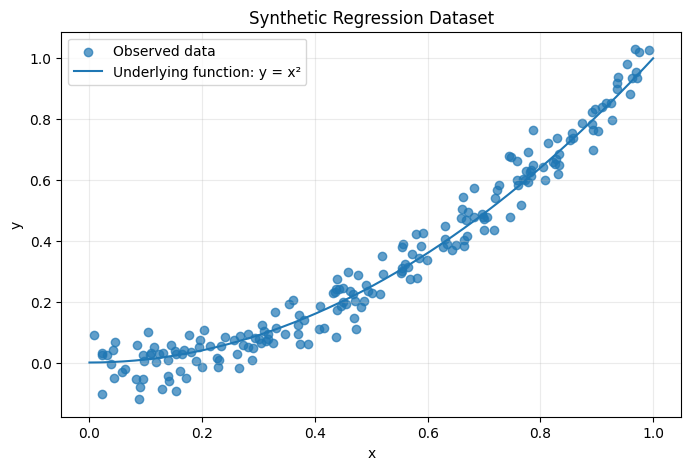

In [5]:
X = data[["x"]].values
y = data["y"].values

plt.figure(figsize=(8, 5))
plt.scatter(X.ravel(), y, alpha=0.7, label="Observed data")
x_line = np.linspace(0, 1, 200)
plt.plot(x_line, x_line**2, label="Underlying function: y = x²")
plt.xlabel("x")
plt.ylabel("y")
plt.title("Synthetic Regression Dataset")
plt.legend()
plt.grid(alpha=0.25)
plt.show()


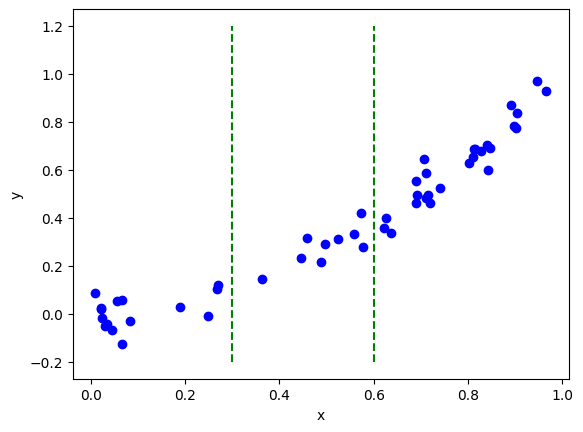

In [6]:
X = np.random.sample(50)
Y = np.array([x**2 + np.random.normal(0, 0.05) for x in X])

plt.xlabel("x")
plt.ylabel("y")

plt.scatter(X, Y, color='b')
plt.plot([0.3, 0.3], [-0.2, 1.2], 'g--')
plt.plot([0.6, 0.6], [-0.2, 1.2], 'g--');


In [7]:
def avg(X, Y, x_min, x_max):
  """Return the average value in (x_min, x_max) range"""
  n = 0    # number of samples in given split
  avg = 0  # average value

  for x, y in zip(X, Y):
    if x >= x_min and x < x_max:
      n += 1
      avg += y

  return avg / n


Text(0.5, 1.0, 'Yusufjon Tolibjonov')

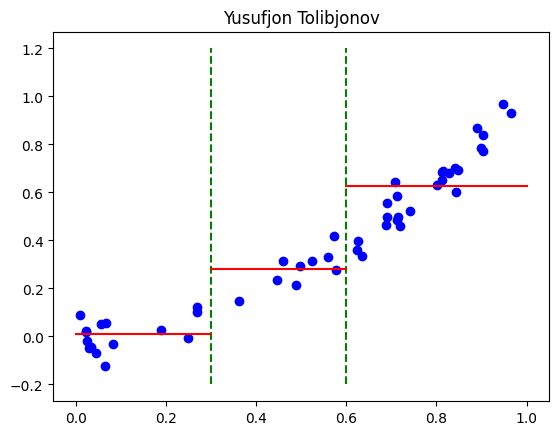

In [10]:
plt.scatter(X, Y, color='b')

plt.plot([0.3, 0.3], [-0.2, 1.2], 'g--')
plt.plot([0.6, 0.6], [-0.2, 1.2], 'g--')

y = avg(X, Y, 0, 0.3)
plt.plot([0.0, 0.3], [y, y], 'r')

y = avg(X, Y, 0.3, 0.6)
plt.plot([0.3, 0.6], [y, y], 'r')

y = avg(X, Y, 0.6, 1)
plt.plot([0.6, 1.0], [y, y], 'r');
plt.title("Yusufjon Tolibjonov")

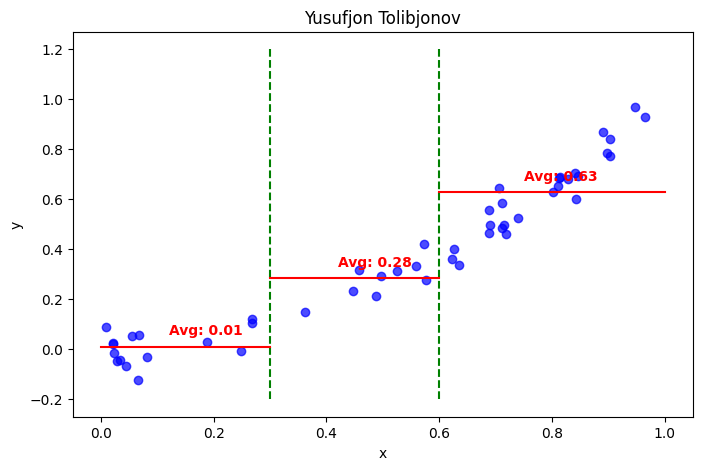

In [12]:
plt.figure(figsize=(8, 5))
plt.scatter(X, Y, color='b', alpha=0.7, label="Observed data")

plt.plot([0.3, 0.3], [-0.2, 1.2], 'g--')
plt.plot([0.6, 0.6], [-0.2, 1.2], 'g--')

# 1-qism
y1 = avg(X, Y, 0, 0.3)
plt.plot([0.0, 0.3], [y1, y1], 'r-')
plt.text(0.12, y1 + 0.05, f"Avg: {y1:.2f}", color='red', fontsize=10, fontweight='bold')

# 2-qism
y2 = avg(X, Y, 0.3, 0.6)
plt.plot([0.3, 0.6], [y2, y2], 'r-')
plt.text(0.42, y2 + 0.05, f"Avg: {y2:.2f}", color='red', fontsize=10, fontweight='bold')

# 3-qism
y3 = avg(X, Y, 0.6, 1)
plt.plot([0.6, 1.0], [y3, y3], 'r-')
plt.text(0.75, y3 + 0.05, f"Avg: {y3:.2f}", color='red', fontsize=10, fontweight='bold')

plt.title("Yusufjon Tolibjonov")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

In [13]:
from sklearn.tree import DecisionTreeRegressor

# create a decision tree regressor
fit = DecisionTreeRegressor()

# and grow it (note that X must be reshaped)
fit.fit(np.reshape(X, (-1, 1)), Y);

# prepare test sample with "newaxis" trick
X_test = np.arange(0.0, 1.0, 0.01)[:, np.newaxis]
Y_test = fit.predict(X_test)


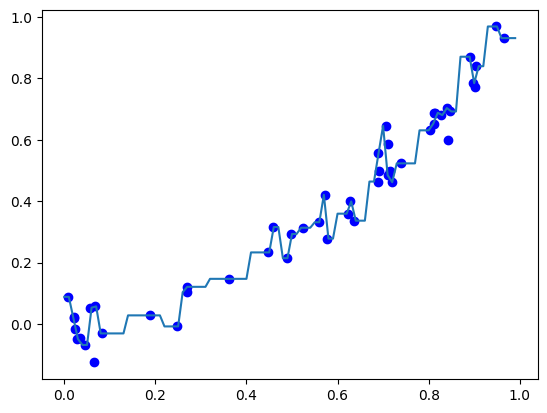

In [14]:
plt.scatter(X, Y, color='b')
plt.plot(X_test, Y_test);


In [15]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor

class TreeCV:
  """Perform a cross-validation for chosen hyperparameter"""

  def __init__(self, X, Y, hp="max_depth"):
    """Save training data"""
    self.X = X    # features
    self.Y = Y    # targets
    self.hp = hp  # hyperparameter


  def set_method(self, hp):
    """Set hyperparameter to use"""
    self.hp = hp


  def cross_me(self, *hp_vals):
    """Perform cross validation for given hyperparameter values"""
    self.scores = []  # the accuracy table
    self.best = None  # the best fit

    best_score = 0

    for hp in hp_vals:
      # create a tree with given hyperparameter cut
      fit = DecisionTreeRegressor(**{self.hp: hp})

      # calculate a cross validation scores and a mean value
      score = cross_val_score(fit, np.reshape(X, (-1, 1)), Y).mean()

      # update best fit if necessary
      if score > best_score:
        self.best = fit
        best_score = score

      self.scores.append([hp, score])

    # train the best fit
    self.best.fit(np.reshape(X, (-1, 1)), Y)


  def plot(self):
    """Plot accuracy as a function of hyperparameter values and best fit"""
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 2, 1)

    plt.xlabel(self.hp)
    plt.ylabel("accuracy")

    plt.plot(*zip(*self.scores))

    plt.subplot(1, 2, 2)

    X_test = np.arange(0.0, 1.0, 0.01)[:, np.newaxis]
    Y_test = self.best.predict(X_test)

    plt.scatter(self.X, self.Y, color='b', marker='.', label="Training data")
    plt.plot(X_test, X_test * X_test, 'g', label="True distribution")
    plt.plot(X_test, Y_test, 'r', label="Decision tree")

    plt.legend()


In [16]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeRegressor

class TreeCV:
  """Perform a cross-validation for chosen hyperparameter"""

  def __init__(self, X, Y, hp="max_depth"):
    """Save training data"""
    self.X = X    # features
    self.Y = Y    # targets
    self.hp = hp  # hyperparameter


  def set_method(self, hp):
    """Set hyperparameter to use"""
    self.hp = hp


  def cross_me(self, *hp_vals):
    """Perform cross validation for given hyperparameter values"""
    self.scores = []  # the accuracy table
    self.best = None  # the best fit

    best_score = 0

    for hp in hp_vals:
      # create a tree with given hyperparameter cut
      fit = DecisionTreeRegressor(**{self.hp: hp})

      # calculate a cross validation scores and a mean value
      score = cross_val_score(fit, np.reshape(X, (-1, 1)), Y).mean()

      # update best fit if necessary
      if score > best_score:
        self.best = fit
        best_score = score

      self.scores.append([hp, score])

    # train the best fit
    self.best.fit(np.reshape(X, (-1, 1)), Y)


  def plot(self):
    """Plot accuracy as a function of hyperparameter values and best fit"""
    plt.figure(figsize=(15, 5))

    plt.subplot(1, 2, 1)

    plt.xlabel(self.hp)
    plt.ylabel("accuracy")

    plt.plot(*zip(*self.scores))

    plt.subplot(1, 2, 2)

    X_test = np.arange(0.0, 1.0, 0.01)[:, np.newaxis]
    Y_test = self.best.predict(X_test)

    plt.scatter(self.X, self.Y, color='b', marker='.', label="Training data")
    plt.plot(X_test, X_test * X_test, 'g', label="True distribution")
    plt.plot(X_test, Y_test, 'r', label="Decision tree")

    plt.legend()


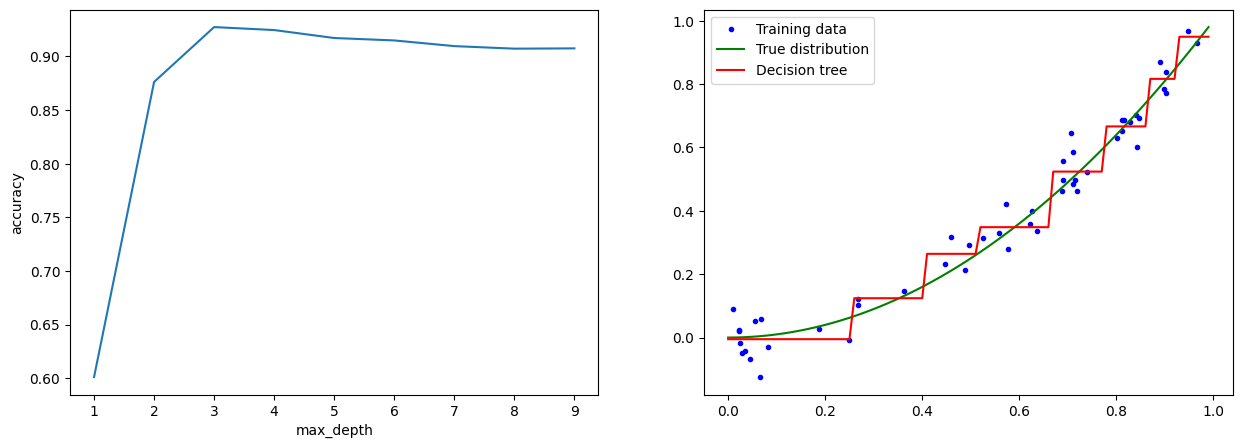

In [17]:
tree_handler = TreeCV(X, Y)
tree_handler.cross_me(*range(1, 10))
tree_handler.plot()


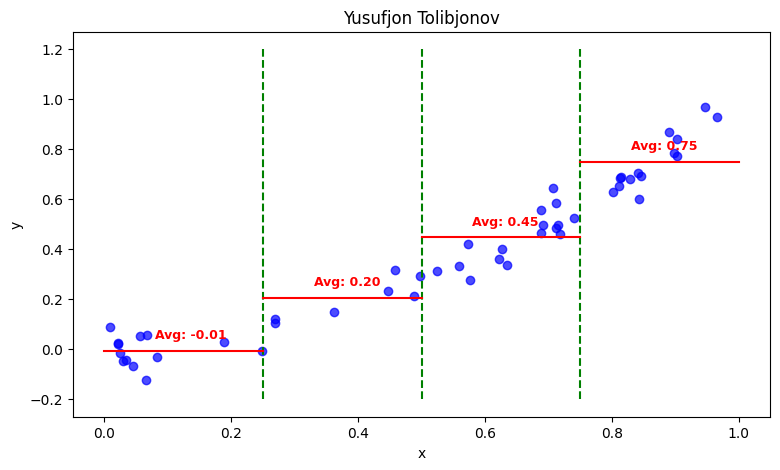

In [18]:
plt.figure(figsize=(9, 5))
plt.scatter(X, Y, color='b', alpha=0.7, label="Observed data")

# 4 ta guruh uchun chegaralar (chiziqlar)
splits = [0.25, 0.50, 0.75]
for s in splits:
    plt.plot([s, s], [-0.2, 1.2], 'g--')

# 1-guruh: [0.0, 0.25)
y1 = avg(X, Y, 0.0, 0.25)
plt.plot([0.0, 0.25], [y1, y1], 'r-')
plt.text(0.08, y1 + 0.05, f"Avg: {y1:.2f}", color='red', fontsize=9, fontweight='bold')

# 2-guruh: [0.25, 0.50)
y2 = avg(X, Y, 0.25, 0.50)
plt.plot([0.25, 0.50], [y2, y2], 'r-')
plt.text(0.33, y2 + 0.05, f"Avg: {y2:.2f}", color='red', fontsize=9, fontweight='bold')

# 3-guruh: [0.50, 0.75)
y3 = avg(X, Y, 0.50, 0.75)
plt.plot([0.50, 0.75], [y3, y3], 'r-')
plt.text(0.58, y3 + 0.05, f"Avg: {y3:.2f}", color='red', fontsize=9, fontweight='bold')

# 4-guruh: [0.75, 1.0]
y4 = avg(X, Y, 0.75, 1.0)
plt.plot([0.75, 1.0], [y4, y4], 'r-')
plt.text(0.83, y4 + 0.05, f"Avg: {y4:.2f}", color='red', fontsize=9, fontweight='bold')

plt.title("Yusufjon Tolibjonov")
plt.xlabel("x")
plt.ylabel("y")
plt.show()

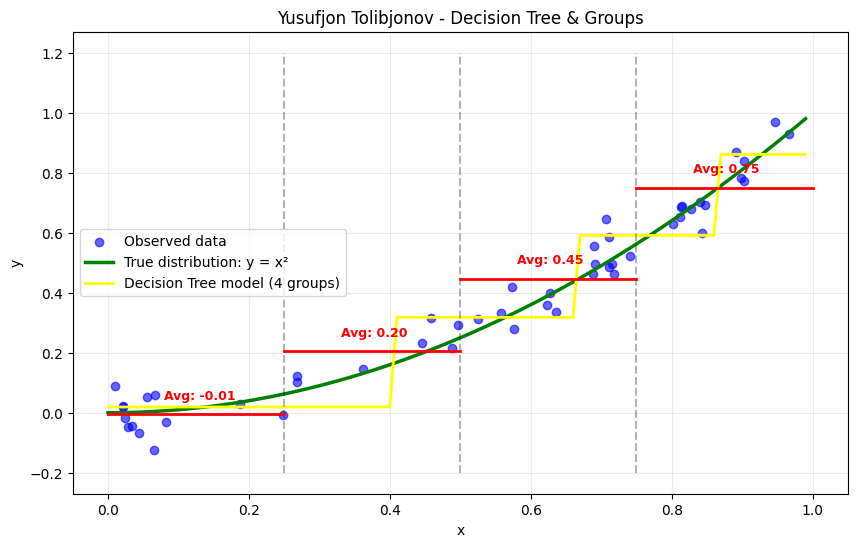

In [22]:
from sklearn.tree import DecisionTreeRegressor

plt.figure(figsize=(10, 6))

# 1. Asosiy kuzatuv ma'lumotlari (scatter)
plt.scatter(X, Y, color='b', alpha=0.6, label="Observed data")

# 2. Haqiqiy taqsimot (True distribution: y = x^2)
X_test = np.arange(0.0, 1.0, 0.01)[:, np.newaxis]
plt.plot(X_test, X_test**2, 'g-', linewidth=2.5, label="True distribution: y = x²")

# 3. Decision Tree Regressor (max_depth=2 yoki 3 qilib 4 ta guruh hosil qilamiz)
fit = DecisionTreeRegressor(max_depth=2)
fit.fit(np.reshape(X, (-1, 1)), Y)
Y_test = fit.predict(X_test)
plt.plot(X_test, Y_test, color='yellow', linestyle='-', linewidth=2, label="Decision Tree model (4 groups)")

# 4. 4 ta qo'lda bo'lingan guruh chegaralari va o'rtachalari
splits = [0.25, 0.50, 0.75]
for s in splits:
    plt.plot([s, s], [-0.2, 1.2], 'k--', alpha=0.3)

# 4 ta qism uchun avg chiziqlar
y1 = avg(X, Y, 0.0, 0.25)
plt.plot([0.0, 0.25], [y1, y1], 'r-', linewidth=2)
plt.text(0.08, y1 + 0.05, f"Avg: {y1:.2f}", color='red', fontsize=9, fontweight='bold')

y2 = avg(X, Y, 0.25, 0.50)
plt.plot([0.25, 0.50], [y2, y2], 'r-', linewidth=2)
plt.text(0.33, y2 + 0.05, f"Avg: {y2:.2f}", color='red', fontsize=9, fontweight='bold')

y3 = avg(X, Y, 0.50, 0.75)
plt.plot([0.50, 0.75], [y3, y3], 'r-', linewidth=2)
plt.text(0.58, y3 + 0.05, f"Avg: {y3:.2f}", color='red', fontsize=9, fontweight='bold')

y4 = avg(X, Y, 0.75, 1.0)
plt.plot([0.75, 1.0], [y4, y4], 'r-', linewidth=2)
plt.text(0.83, y4 + 0.05, f"Avg: {y4:.2f}", color='red', fontsize=9, fontweight='bold')

plt.title("Yusufjon Tolibjonov - Decision Tree & Groups")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(alpha=0.25)
plt.show()